# 07 — COREG inductif, traction, deux validations

Implémentation autorisée après le cadrage des notebooks 05/06. Trois régressions
séparées YS/UTS/allongement, 16 entrées numériques + procédé, médiane. Pools
naturels sans y seulement ; Charpy exclu ici car aucune ligne sans énergie avec
température connue. Aucun masquage artificiel de labels dans ce benchmark.

Méthode fixée avant calcul : reprendre les plis externes/interne existants,
réajuster le preprocessing sur le vrai train, régler k=3/5/9/15 sur MAE interne,
évaluer COREG et les contrôles sur les mêmes IDs externes, exporter les modèles,
puis régler/refit sur tous les labels pour l'inférence. Les refits complets ne
servent jamais à évaluer les plis. Trois bases de seeds pour une sensibilité
au tirage, sans sélectionner la meilleure à partir de leurs scores externes.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import Memory, parallel_config
from threadpoolctl import threadpool_limits

SEED = 42
N_JOBS = 3  # recherches parallèles ; chaque forêt utilise un seul worker
PRIMARY_SET = 'A1b_16'
PRIMARY_IMPUTER = 'median'
TARGETS = ['yield_strength', 'uts', 'elongation', 'charpy_J']
CAT = 'weld_process'
PROCESS_COL = CAT
CORE13 = ['C', 'Si', 'Mn', 'S', 'P', 'current_A', 'voltage_V',
          'heat_input_kJmm', 'interpass_C', 'pwht_temp_C', 'pwht_time_h',
          'O_ppm', 'N_ppm']
CORE16 = CORE13 + ['Ni', 'Cr', 'Mo']
NONNEG = CORE16  # la température d'essai peut être négative
TARGET_UNITS = {'yield_strength': 'MPa', 'uts': 'MPa',
                'elongation': 'points de %', 'charpy_J': 'J'}
TARGET_NAMES = {'yield_strength': "Limite d'élasticité", 'uts': 'Résistance maximale',
                'elongation': 'Allongement', 'charpy_J': 'Énergie Charpy — exploratoire'}
MODEL_NAMES = {'median_y': 'Médiane de y', 'ridge': 'Ridge', 'svr_rbf': 'SVR RBF',
               'random_forest': 'Random Forest', 'knn': 'kNN'}
PARAM_GRIDS = {
    'median_y': {},
    'ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'svr_rbf': {'model__regressor__C': [1, 10, 100],
                'model__regressor__gamma': ['scale', 0.05],
                'model__regressor__epsilon': [0.05, 0.2]},
    'random_forest': {'model__min_samples_leaf': [1, 2, 5],
                     'model__max_depth': [None, 10],
                     'model__max_features': [0.5, 1.0]},
    'knn': {'model__n_neighbors': [3, 5, 9, 15], 'model__p': [1, 2]},
}

def numeric_features(target):
    if target not in TARGETS:
        raise ValueError(f'Cible non prévue : {target}')
    return list(CORE16) + (['charpy_temp_C'] if target == 'charpy_J' else [])

def task_features(target):
    return numeric_features(target) + [CAT]

def eligible_rows(frame, target):
    # La température d'essai est une condition connue pour E(T), jamais imputée
    # pour fabriquer un couple Charpy dont la condition d'essai serait inconnue.
    mask = frame['in_strict13'] & frame[target].notna()
    if target == 'charpy_J':
        mask &= frame.charpy_temp_C.notna()
    return frame.loc[mask].copy()

def regression_metrics(y, prediction):
    y, prediction = np.asarray(y, float), np.asarray(prediction, float)
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError('Labels/prédictions non finis.')
    return {'MAE': float(mean_absolute_error(y, prediction)),
            'RMSE': float(mean_squared_error(y, prediction) ** 0.5),
            'R2': float(r2_score(y, prediction)) if np.ptp(y)>0 else np.nan}

from sklearn.model_selection import KFold, GroupKFold
from scipy.stats import spearmanr
import cloudpickle
import copy
import subprocess
import sys
import os

def balanced_assignment(n, folds, seed):
    # Handles small/empty unlabeled pools; no label values are consulted.
    result=np.empty(n,dtype=int)
    order=np.random.default_rng(seed).permutation(n)
    result[order]=np.arange(n)%folds
    return result

def build_random_plan(frame,target,seed=SEED):
    candidate=frame.loc[frame.in_strict13 & ~frame.is_duplicate_excess].copy()
    if target=='charpy_J': candidate=candidate.loc[candidate.charpy_temp_C.notna()]
    candidate=candidate.sort_values('raw_row_id').reset_index(drop=True)
    plan=candidate[['raw_row_id','group']].copy()
    plan['target']=target
    plan['label_state']=np.where(candidate[target].notna(),'labeled','unlabeled')
    plan['outer_fold']=-1
    known=np.flatnonzero(candidate[target].notna())
    for fold,(_,va) in enumerate(KFold(5,shuffle=True,random_state=seed).split(known)):
        plan.loc[known[va],'outer_fold']=fold
    unknown=np.flatnonzero(candidate[target].isna())
    plan.loc[unknown,'outer_fold']=balanced_assignment(len(unknown),5,seed+100)
    for outer in range(5):
        col=f'inner_fold_when_outer{outer}'; plan[col]=-1
        labeled_train=np.flatnonzero((plan.outer_fold!=outer)&(plan.label_state=='labeled'))
        for fold,(_,va) in enumerate(KFold(3,shuffle=True,random_state=seed+outer+1).split(labeled_train)):
            plan.loc[labeled_train[va],col]=fold
        unlabeled_train=np.flatnonzero((plan.outer_fold!=outer)&(plan.label_state=='unlabeled'))
        plan.loc[unlabeled_train,col]=balanced_assignment(len(unlabeled_train),3,seed+1000+outer)
    assert not plan.duplicated('raw_row_id').any()
    return plan

def permitted_ids(plan,outer,inner=None):
    # Strict inductive access. Outer/inner validation inputs are not in the pool.
    train=plan.outer_fold!=outer
    if inner is not None:
        train &= plan[f'inner_fold_when_outer{outer}']!=inner
    labeled=plan.label_state=='labeled'
    valid=(plan.outer_fold==outer) if inner is None else (
        (plan.outer_fold!=outer)&(plan[f'inner_fold_when_outer{outer}']==inner))
    return {'labeled_train':plan.loc[train&labeled,'raw_row_id'].to_numpy(),
            'unlabeled_train':plan.loc[train&~labeled,'raw_row_id'].to_numpy(),
            'labeled_valid':plan.loc[valid&labeled,'raw_row_id'].to_numpy()}

def random_partitions(frame,plan,outer):
    access=permitted_ids(plan,outer)
    train=frame.loc[frame.raw_row_id.isin(access['labeled_train'])].sort_values('raw_row_id').reset_index(drop=True)
    valid=frame.loc[frame.raw_row_id.isin(access['labeled_valid'])].sort_values('raw_row_id').reset_index(drop=True)
    assert set(train.raw_row_id).isdisjoint(valid.raw_row_id)
    assert train[plan.target.iloc[0]].notna().all() and valid[plan.target.iloc[0]].notna().all()
    return train,valid

def random_inner_splits(train,plan,outer):
    folds=plan.set_index('raw_row_id').loc[train.raw_row_id,f'inner_fold_when_outer{outer}'].to_numpy()
    assert set(folds)=={0,1,2}
    return [(np.flatnonzero(folds!=k),np.flatnonzero(folds==k)) for k in range(3)]

def condition_signature(frame,columns):
    # Exact available values, including an explicit unknown marker; never impute.
    # Equality of partial signatures is a proxy, not proof of the same specimen.
    def token(v):
        if pd.isna(v): return None
        return v.item() if isinstance(v,np.generic) else v
    return frame[columns].apply(lambda row:json.dumps([token(v) for v in row],
                               ensure_ascii=False,separators=(',',':')),axis=1)

def train_seen_signatures(train,valid,columns):
    return condition_signature(valid,columns).isin(set(condition_signature(train,columns)))

def detached_pipeline(fitted):
    model=copy.deepcopy(fitted)
    model.memory=None
    return model

def dump_pipeline(fitted,path,metadata,probe):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    exported=detached_pipeline(fitted)
    with path.open('wb') as stream: cloudpickle.dump(exported,stream,protocol=5)
    with path.open('rb') as stream: loaded=cloudpickle.load(stream)
    np.testing.assert_allclose(loaded.predict(probe),fitted.predict(probe),rtol=1e-10,atol=1e-8)
    metadata=dict(metadata,artifact_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                  serialization='cloudpickle_protocol5',versions=VERSIONS)
    path.with_suffix('.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False)+'\n')
    return metadata
def outer_partitions(frame, target, outer_fold):
    eligible = eligible_rows(frame, target)
    train = eligible.loc[eligible.outer_fold != outer_fold].reset_index(drop=True)
    valid = eligible.loc[eligible.outer_fold == outer_fold].reset_index(drop=True)
    if train.empty or valid.empty:
        raise ValueError(f'Partition vide : {target}, pli {outer_fold}')
    if not set(train.group).isdisjoint(valid.group):
        raise AssertionError('Un groupe externe est partagé entre train et validation.')
    return train, valid

def inner_splits(train, outer_fold):
    col = f'inner_fold_when_outer{outer_fold}'
    if not set(train[col].unique()).issubset({0, 1, 2}):
        raise AssertionError('Les lignes externes ne doivent pas entrer dans les plis internes.')
    splits = []
    for inner_fold in range(3):
        tr = np.flatnonzero(train[col].to_numpy() != inner_fold)
        va = np.flatnonzero(train[col].to_numpy() == inner_fold)
        if len(tr) < 15 or len(va) < 2:
            raise ValueError('Effectif interne insuffisant pour les grilles prévues.')
        if not set(train.iloc[tr].group).isdisjoint(train.iloc[va].group):
            raise AssertionError('Un groupe interne est partagé.')
        splits.append((tr, va))
    return splits


def grouped_full_splits(train):
    partitions=list(GroupKFold(5).split(train,groups=train.group))
    for tr,va in partitions:
        assert set(train.iloc[tr].group).isdisjoint(train.iloc[va].group)
    return partitions

def grouped_access(frame,target,outer,inner=None):
    candidate=frame.loc[frame.in_strict13 & ~frame.is_duplicate_excess].copy()
    if target=='charpy_J': candidate=candidate.loc[candidate.charpy_temp_C.notna()]
    allowed=candidate.outer_fold!=outer
    valid=candidate.outer_fold==outer
    if inner is not None:
        allowed &= candidate[f'inner_fold_when_outer{outer}']!=inner
        valid=(candidate.outer_fold!=outer)&(candidate[f'inner_fold_when_outer{outer}']==inner)
    labeled=candidate[target].notna()
    training=candidate.loc[allowed & labeled]
    pool=candidate.loc[allowed & ~labeled]
    validation=candidate.loc[valid & labeled]
    assert set(training.group).isdisjoint(validation.group)
    assert set(pool.group).isdisjoint(validation.group)
    assert set(training.raw_row_id).isdisjoint(pool.raw_row_id)
    return training,pool,validation

SSL_TARGETS=TARGETS[:3]
K_GRID=[3,5,9,15]
PROTOCOLS=["random","grouped"]


In [2]:
class FoldPreprocessor(BaseEstimator, TransformerMixin):
    """À ajuster sur les lignes d'entraînement d'un pli uniquement.

    1. standardisation des entrées numériques (moyenne/écart-type du train, NaN ignorés) ;
    2. one-hot du procédé (catégories du train ; inconnue -> vecteur nul) ;
    3. imputation : 'iterative' (IterativeImputer/BayesianRidge, init médiane, ordre ascendant,
       max_iter=100, tol=1e-3, random_state=42, bornes physiques >= 0) ou 'median' ;
    4. PWHT : un couple (température, durée) imputé est projeté sur le couple réel du train
       le plus proche (distance en écarts-types du train), en respectant une valeur observée.
    Une colonne entièrement absente du train est refusée plutôt que fabriquée.
    Sortie : entrées standardisées + indicatrices du procédé. Les cibles n'entrent jamais ici.
    """

    def __init__(self, num_cols, cat_col=PROCESS_COL, method='median', max_iter=100,
                 tol=1e-3, random_state=SEED):
        self.num_cols, self.cat_col, self.method = num_cols, cat_col, method
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state

    def _encode(self, X):
        if 'charpy_temp_C' in self.num_cols and X['charpy_temp_C'].isna().any():
            raise ValueError("Température Charpy requise ; aucune condition d'essai ne peut être imputée.")
        Z = (X[self.num_cols].to_numpy(float) - self.mu_) / self.sd_
        C = np.stack([(X[self.cat_col] == c).to_numpy(float) for c in self.cats_], axis=1) \
            if self.cat_col else np.empty((len(X), 0))
        return np.hstack([Z, C])

    def fit(self, X, y=None):
        Xn = X[self.num_cols].astype(float)
        empty = Xn.columns[Xn.notna().sum() == 0].tolist()
        if empty:
            raise ValueError(f'Colonnes entièrement absentes du train : {empty}')
        self.mu_ = Xn.mean().to_numpy()
        self.sd_ = Xn.std(ddof=0).replace(0, 1).to_numpy()
        self.cats_ = sorted(X[self.cat_col].dropna().unique()) if self.cat_col else []
        Z = self._encode(X)
        lo = np.full(Z.shape[1], -np.inf)
        for i, c in enumerate(self.num_cols):
            if c in NONNEG:
                lo[i] = (0 - self.mu_[i]) / self.sd_[i]
        if self.method == 'iterative':
            self.imp_ = IterativeImputer(estimator=BayesianRidge(), initial_strategy='median',
                                         imputation_order='ascending', max_iter=self.max_iter,
                                         tol=self.tol, random_state=self.random_state,
                                         skip_complete=False, min_value=lo, keep_empty_features=True)
        elif self.method == 'median':
            self.imp_ = SimpleImputer(strategy='median', keep_empty_features=True)
        else:
            raise ValueError(self.method)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            self.imp_.fit(Z)
        self.converged_ = (self.method != 'iterative') or (self.imp_.n_iter_ < self.max_iter)
        self.n_iter_ = getattr(self.imp_, 'n_iter_', 0)
        if not self.converged_:
            raise RuntimeError('Imputation itérative non convergée : réviser le schéma dans le train.')
        # couples PWHT réels du train
        self.pw_idx_ = [self.num_cols.index(c) for c in ('pwht_temp_C', 'pwht_time_h')
                        if c in self.num_cols]
        if len(self.pw_idx_) == 2:
            P = Z[:, self.pw_idx_]
            self.pw_pairs_ = np.unique(P[~np.isnan(P).any(axis=1)], axis=0)
            if len(self.pw_pairs_) == 0:
                raise ValueError('Aucun couple PWHT complet dans le train.')
        return self

    def transform(self, X):
        Z = self._encode(X)
        miss = np.isnan(Z)
        out = self.imp_.transform(Z)
        if len(self.pw_idx_) == 2 and len(self.pw_pairs_):
            i, j = self.pw_idx_
            for r in np.where(miss[:, i] | miss[:, j])[0]:
                cand = self.pw_pairs_
                if not miss[r, i]:   # température observée : couples compatibles seulement
                    cand = cand[np.isclose(cand[:, 0], Z[r, i])]
                if not miss[r, j]:
                    cand = cand[np.isclose(cand[:, 1], Z[r, j])]
                if len(cand) == 0:
                    raise ValueError(f'Aucun couple PWHT compatible pour la ligne {X.index[r]}.')
                best = cand[np.argmin(((cand - out[r, [i, j]]) ** 2).sum(axis=1))]
                out[r, i] = Z[r, i] if not miss[r, i] else best[0]
                out[r, j] = Z[r, j] if not miss[r, j] else best[1]
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([str(c) for c in self.num_cols] + [f'{self.cat_col}={c}' for c in self.cats_], dtype=object)

## COREG et variante documentée

Deux kNN uniformes L1/L2 sur les mêmes X. Confiance : gain local de SSE sur le
jeu courant du source (incluant ses pseudo-labels) après ajout temporaire de
sa propre estimation ; envoyer le candidat retenu à l'autre kNN. Moyenne des
deux régressions à la sortie. La mise à jour uniforme du voisin remplacé est
exactement testée contre le refit explicite. La confiance ne garantit pas un
gain d'erreur hors train. [Source : Zhou et Li 2005](https://www.ijcai.org/Proceedings/05/Papers/0689.pdf).

Variante du pool : retirer les représentations déjà présentes dans le vrai
train, dédupliquer X transformé, raw ID minimal représentant. Les répétitions
de vrais labels sont conservées ; égalité de représentation n'est pas une
identité physique prouvée. Cette politique et L1/L2 sont des choix du projet.

100 candidats maximum actifs, 100 tours maximum, recompléter après acceptation.
L1 sélectionne avant L2 ; aucune collision ; échanges après les deux sélections.
Gain > 1e-12 × max(1,var(y_train)) × k. Égalités : position immuable, vrais labels
puis pool triés par raw ID. Arrêt sans gain dans le pool actif, pool épuisé ou
limite : cela ne prouve pas qu'aucun candidat non examiné serait utile.


In [3]:
from sklearn.base import RegressorMixin
from sklearn.utils.validation import check_is_fitted
from scipy.spatial.distance import cdist


def stable_neighbors(distances, reference_indices, k):
    """Exact ranks: distance then immutable initial position, no random tie-break."""
    references=np.sort(np.asarray(reference_indices,dtype=int))
    return references[np.argsort(distances[:,references],axis=1,kind='stable')[:,:k]]


def local_candidate_gains(D, active, labels, candidates, k):
    """Eq.2 gain from inserting each own prediction into its own regressor.

    The kNN is uniform. One insertion replaces only the previous kth neighbor
    where the candidate enters the k nearest; this is an exact update, not an
    approximation of the temporary refit. Omega and labels use current Lj,
    including already-added pseudo-labels, as in the source algorithm.
    """
    references=np.flatnonzero(active)
    candidates=np.asarray(candidates,dtype=int)
    neighbors=stable_neighbors(D[references],references,k)
    current=np.full(len(active),np.nan)
    current[references]=labels[neighbors].mean(axis=1)
    last=np.full(len(active),-1,dtype=int);last[references]=neighbors[:,-1]
    omega=stable_neighbors(D[candidates],references,k)
    estimates=labels[omega].mean(axis=1)
    previous_last=last[omega]
    new_distance=D[candidates[:,None],omega]
    previous_distance=D[omega,previous_last]
    enters=(new_distance<previous_distance)|((new_distance==previous_distance)&
        (candidates[:,None]<previous_last))
    previous=current[omega]
    revised=previous+enters*(estimates[:,None]-labels[previous_last])/k
    gains=((labels[omega]-previous)**2-(labels[omega]-revised)**2).sum(axis=1)
    return gains,estimates,omega


class COREGRegressor(RegressorMixin,BaseEstimator):
    """COREG with uniform L1/L2 kNN, deterministic ranks and a unique-X pool.

    Variant: deduplicate transformed pool X and remove X already in true train,
    to prevent replicated missing-feature patterns from gaining artificial weight.
    Original true labels/replicates are all retained. No validation data accepted.
    """
    def __init__(self,n_neighbors=5,max_iter=100,pool_size=100,random_state=42,
                 gain_tol=1e-12,output='mean'):
        self.n_neighbors=n_neighbors;self.max_iter=max_iter;self.pool_size=pool_size
        self.random_state=random_state;self.gain_tol=gain_tol;self.output=output

    def fit(self,X,y,unlabeled_X=None,train_ids=None,pool_ids=None):
        X=np.asarray(X,dtype=float);y=np.asarray(y,dtype=float)
        if X.ndim!=2 or y.shape!=(len(X),) or not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError('Training features/labels must be finite and aligned.')
        if not 1<=self.n_neighbors<=len(X) or self.max_iter<0 or self.pool_size<1 or self.gain_tol<0:
            raise ValueError('Invalid neighbor/iteration/pool parameters.')
        if self.output not in ['mean','first','second']:raise ValueError(self.output)
        U=np.empty((0,X.shape[1])) if unlabeled_X is None else np.asarray(unlabeled_X,float)
        if U.ndim!=2 or U.shape[1]!=X.shape[1] or not np.isfinite(U).all():
            raise ValueError('Unlabeled features must be finite and use the same columns.')
        train_ids=np.arange(len(X)) if train_ids is None else np.asarray(train_ids,int)
        pool_ids=np.arange(len(X),len(X)+len(U)) if pool_ids is None else np.asarray(pool_ids,int)
        if train_ids.shape!=(len(X),) or pool_ids.shape!=(len(U),):raise ValueError('IDs not aligned.')
        if len(np.unique(train_ids))!=len(train_ids) or len(np.unique(pool_ids))!=len(pool_ids):
            raise ValueError('Duplicate raw IDs.')
        if set(train_ids)&set(pool_ids):raise ValueError('Training/pool raw IDs overlap.')
        # Label values are never consulted for deduplication. Equality means same
        # representation, not certified physical identity of a weld.
        seen={tuple(row) for row in X}; keep=[]; dropped=[]
        for i in np.argsort(pool_ids,kind='stable'):
            key=tuple(U[i])
            if key in seen:dropped.append(int(pool_ids[i]))
            else:seen.add(key);keep.append(i)
        self.pool_original_n_=len(U);self.pool_usable_n_=len(keep)
        self.dropped_pool_ids_=dropped
        self.train_ids_=train_ids.copy();self.allowed_pool_ids_=pool_ids.copy()
        U=U[keep];pool_ids=pool_ids[keep]
        points=np.vstack([X,U]);ids=np.concatenate([train_ids,pool_ids])
        n=len(X);total=len(points);self.n_features_in_=X.shape[1]
        self.gain_threshold_=self.gain_tol*max(1.,float(np.var(y)))*self.n_neighbors
        active=[np.arange(total)<n,np.arange(total)<n]
        values=[np.concatenate([y,np.full(len(U),np.nan)]) for _ in range(2)]
        self.pseudo_labels_=[];self.iteration_log_=[];self.n_iter_=0
        remaining=np.arange(n,total,dtype=int);batch=np.array([],dtype=int)
        rng=np.random.default_rng(self.random_state)
        self.stop_reason_='no_eligible_pool' if len(U)==0 else 'max_iter'
        if self.max_iter>0 and len(U):
            distances=[cdist(points,points,'cityblock'),cdist(points,points,'euclidean')]
            for iteration in range(1,self.max_iter+1):
                unseen=np.setdiff1d(remaining,batch,assume_unique=True)
                need=min(self.pool_size-len(batch),len(unseen))
                if need:batch=np.sort(np.concatenate([batch,rng.choice(unseen,size=need,replace=False)]))
                if not len(batch):self.stop_reason_='pool_exhausted';break
                choices=[];available=batch.copy();best_gains=[]
                for source in range(2):
                    if not len(available):best_gains.append(np.nan);continue
                    gains,estimates,omega=local_candidate_gains(distances[source],active[source],
                        values[source],available,self.n_neighbors)
                    best=float(gains.max());best_gains.append(best)
                    if best<=self.gain_threshold_:continue
                    # Equal within the fixed tolerance -> smallest immutable position.
                    j=np.flatnonzero((gains>self.gain_threshold_)&(gains>=best-self.gain_threshold_))[0]
                    candidate=int(available[j]);destination=1-source
                    choices.append((source,destination,candidate,float(estimates[j]),float(gains[j])))
                    neighborhood=omega[j]
                    self.pseudo_labels_.append({'iteration':iteration,'raw_row_id':int(ids[candidate]),
                        'source':source+1,'destination':destination+1,'source_p':source+1,
                        'pseudo_y':float(estimates[j]),'local_gain':float(gains[j]),
                        'neighbor_raw_row_ids':json.dumps(ids[neighborhood].tolist()),
                        'pseudo_neighbors_n':int((neighborhood>=n).sum())})
                    available=available[available!=candidate]
                self.n_iter_=iteration
                self.iteration_log_.append({'iteration':iteration,'candidates_examined':len(batch),
                    'accepted':len(choices),'remaining_before':len(remaining),
                    'best_gain_L1':best_gains[0],
                    'best_gain_L2':best_gains[1] if len(best_gains)>1 else np.nan})
                if not choices:self.stop_reason_='no_positive_gain_in_active_pool';break
                accepted=[]
                for source,destination,candidate,prediction,gain in choices:
                    active[destination][candidate]=True;values[destination][candidate]=prediction
                    accepted.append(candidate)
                remaining=remaining[~np.isin(remaining,accepted)]
                batch=batch[~np.isin(batch,accepted)]
                if not len(remaining):self.stop_reason_='pool_exhausted';break
        self.X_models_=[points[a].copy() for a in active]
        self.y_models_=[v[a].copy() for v,a in zip(values,active)]
        self.model_raw_ids_=[ids[a].copy() for a in active]
        self.n_pseudo_=len(self.pseudo_labels_)
        if self.max_iter==0:self.stop_reason_='supervised_control'
        return self

    def predict_components(self,X):
        check_is_fitted(self,'X_models_')
        X=np.asarray(X,float)
        if X.ndim!=2 or X.shape[1]!=self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError('Prediction features must be finite and aligned.')
        result=[]
        for j,metric in enumerate(['cityblock','euclidean']):
            distances=cdist(X,self.X_models_[j],metric)
            order=np.argsort(distances,axis=1,kind='stable')[:,:self.n_neighbors]
            result.append(self.y_models_[j][order].mean(axis=1))
        return np.column_stack(result)

    def predict(self,X):
        parts=self.predict_components(X)
        return parts.mean(axis=1) if self.output=='mean' else parts[:,0 if self.output=='first' else 1]


In [4]:

def full_group_plan(frame,target):
    p=frame[['raw_row_id','group']].copy().sort_values('raw_row_id').reset_index(drop=True)
    known=frame.set_index('raw_row_id').loc[p.raw_row_id,target].notna().to_numpy()
    p['target']=target;p['label_state']=np.where(known,'labeled','unlabeled');p['outer_fold']=-1
    ids=np.flatnonzero(known);groups=p.loc[ids,'group'].to_numpy()
    for outer,(_,va) in enumerate(GroupKFold(5).split(ids,groups=groups)):
        p.loc[ids[va],'outer_fold']=outer
    group_map=p.loc[known].set_index('group').outer_fold.to_dict()
    only_U=sorted(set(p.group)-set(group_map))
    group_map.update(dict(zip(only_U,balanced_assignment(len(only_U),5,1142))))
    p['outer_fold']=p.group.map(group_map).astype(int)
    assert p.groupby('group').outer_fold.nunique().max()==1
    return p

def access_frames(protocol,target,outer,inner=None,full=False):
    if full or protocol=='random':
        plan=full_plans[(protocol,target)] if full else random_plans[target]
        ids=permitted_ids(plan,outer,inner)
        def rows(name):
            return data.loc[data.raw_row_id.isin(ids[name])].sort_values('raw_row_id').reset_index(drop=True)
        train,pool,valid=rows('labeled_train'),rows('unlabeled_train'),rows('labeled_valid')
        permitted=(plan.outer_fold!=outer)
        if inner is not None:permitted &= plan[f'inner_fold_when_outer{outer}']!=inner
        assert set(train.raw_row_id)|set(pool.raw_row_id)==set(plan.loc[permitted,'raw_row_id'])
    else:
        train,pool,valid=grouped_access(data,target,outer,inner)
        train=train.sort_values('raw_row_id').reset_index(drop=True)
        pool=pool.sort_values('raw_row_id').reset_index(drop=True)
        valid=valid.sort_values('raw_row_id').reset_index(drop=True)
    assert set(train.raw_row_id).isdisjoint(valid.raw_row_id)
    assert set(pool.raw_row_id).isdisjoint(valid.raw_row_id)
    assert set(train.raw_row_id).isdisjoint(pool.raw_row_id)
    assert train[target].notna().all() and valid[target].notna().all() and pool[target].isna().all()
    if protocol=='grouped':
        assert set(train.group).isdisjoint(valid.group) and set(pool.group).isdisjoint(valid.group)
    return train,pool,valid

def prepare_context(train,pool,valid,target):
    features=task_features(target)
    pre=FoldPreprocessor(numeric_features(target),method='median').fit(train[features])
    Z=pre.transform(train[features])
    U=pre.transform(pool[features]) if len(pool) else np.empty((0,Z.shape[1]))
    V=pre.transform(valid[features]) if len(valid) else np.empty((0,Z.shape[1]))
    return {'pre':pre,'Z':Z,'U':U,'V':V,'y':train[target].to_numpy(float),
        'train_ids':train.raw_row_id.to_numpy(),'pool_ids':pool.raw_row_id.to_numpy()}

def seed_for(protocol,target,outer,inner=None,stage='outer',base=42):
    offsets={'inner':0,'outer':5000,'full_cv':10000,'full':15000,'seed_sensitivity':5000}
    return int(base+100000*PROTOCOLS.index(protocol)+10000*SSL_TARGETS.index(target)+
               offsets[stage]+100*outer+(0 if inner is None else inner))

def fit_coreg(ctx,k,seed,semi=True,output='mean'):
    est=COREGRegressor(n_neighbors=k,max_iter=100 if semi else 0,pool_size=100,
        random_state=seed,gain_tol=1e-12,output=output)
    est.fit(ctx['Z'],ctx['y'],ctx['U'] if semi else None,
        train_ids=ctx['train_ids'],pool_ids=ctx['pool_ids'] if semi else None)
    return est

def context_candidates(ctx,k,seed):
    started=time.perf_counter();semi=fit_coreg(ctx,k,seed)
    control=fit_coreg(ctx,k,seed,semi=False)
    components=control.predict_components(ctx['V'])
    return k,semi,{'coreg':semi.predict(ctx['V']),'knn_pair':components.mean(axis=1),
        'knn_l1':components[:,0],'knn_l2':components[:,1]},time.perf_counter()-started

def record_fit(model,context,elapsed):
    fit_rows.append(dict(context,n_train=len(model.train_ids_),n_pool_raw=model.pool_original_n_,
        n_pool_unique=model.pool_usable_n_,n_pseudo=model.n_pseudo_,iterations=model.n_iter_,
        stop_reason=model.stop_reason_,gain_threshold=model.gain_threshold_,elapsed_seconds=elapsed))
    for row in model.pseudo_labels_:pseudo_rows.append(dict(context,**row))
    for row in model.iteration_log_:iteration_rows.append(dict(context,**row))

def persist_logs():
    save_csv(pd.DataFrame(fit_rows),'fit_audit.csv')
    save_csv(pd.DataFrame(pseudo_rows),'pseudo_labels.csv')
    save_csv(pd.DataFrame(iteration_rows),'iteration_history.csv')

def evaluate_candidates(train,pool,valid,protocol,target,outer,inner,stage):
    ctx=prepare_context(train,pool,valid,target)
    seed=seed_for(protocol,target,outer,inner,stage)
    with parallel_config(backend='threading'),threadpool_limits(limits=1):
        results=joblib.Parallel(n_jobs=3)(joblib.delayed(context_candidates)(ctx,k,seed) for k in K_GRID)
    rows=[]
    for k,model,predictions,elapsed in results:
        context={'protocol':protocol,'target':target,'outer_fold':outer,'inner_fold':-1 if inner is None else inner,
            'stage':stage,'k':k,'seed':seed}
        record_fit(model,context,elapsed)
        for method,pred in predictions.items():
            rows.append(dict(context,method=method,**regression_metrics(valid[target],pred)))
    return rows

def choose_neighbors(rows):
    means=pd.DataFrame(rows).groupby(['method','k'],sort=True).MAE.mean().reset_index()
    return {method:int(g.loc[g.MAE.idxmin(),'k']) for method,g in means.groupby('method')},means

def as_pipeline(pre,model):
    return Pipeline([('preprocess',copy.deepcopy(pre)),('model',model)])

def export_model(pipeline,protocol,target,method,train,pool,probe,k,role,outer=-1,cv_mae=None):
    folder=MODELS/protocol/('outer' if role=='outer_train_only' else 'full_fit')
    path=folder/f'{target}_{method}{"_fold"+str(outer) if outer>=0 else ""}.pkl'
    model=pipeline.named_steps['model']
    metadata={'role':role,'protocol':protocol,'target':target,'method':method,'outer_fold':outer,
        'features':task_features(target),'unit':TARGET_UNITS[target],'numeric_features':CORE16,
        'imputer':'median','train_raw_row_ids':train.raw_row_id.tolist(),'pool_raw_row_ids':pool.raw_row_id.tolist(),
        'train_groups':sorted(train.group.unique()),'pool_groups':sorted(pool.group.unique()),
        'k':k,'p':[1,2],'max_iter':model.max_iter,'pool_size':100,'seed':model.random_state,
        'n_pseudo':model.n_pseudo_,'stop_reason':model.stop_reason_,'selection_CV_MAE':cv_mae,
        'raw_sha256':preparation_manifest['raw_sha256'],'inductive':True,
        'do_not_use_for_fold_evaluation':role!='outer_train_only','independent_test_evaluated':False,
        'pool_policy':'unique transformed X excluding true-train X; smallest raw ID representative'}
    saved=dump_pipeline(pipeline,path,metadata,probe)
    entry={'protocol':protocol,'target':target,'method':method,'role':role,'outer_fold':outer,
        'k':k,'n_pseudo':model.n_pseudo_,'path':str(path.relative_to(PROJECT_ROOT)),
        'sha256':saved['artifact_sha256'],'selection_CV_MAE':cv_mae}
    artifact_rows.append(entry);return entry


## Données, pipelines et accès inductifs

Master et hashes des expériences précédentes vérifiés. Encodages/units du master
préservés : C/Si/Mn/S/P/Ni/Cr/Mo % massique ; O/N ppm ; courant A, tension V,
apport thermique kJ/mm, températures °C, durée PWHT h. Cibles MPa/MPa/points de %.
Pas d'autres sorties, ID, groupe, dureté/FATT50 ou microstructure dans X.

Statistiques numériques et catégories du vrai train → one-hot → médiane train
→ garde PWHT. Transformations figées pour tout le pool et toutes les itérations.
Les tableaux U transmis au modèle contiennent uniquement X, aucun y ni autre
sortie. Chaque train interne exclut la validation interne et externe et leurs U.
En protocole groupé, aucun groupe de validation dans le train ou le pool.


In [5]:
PROJECT_ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'sujet.md').is_file())
DATA=PROJECT_ROOT/'data/processed/modeling'
DIAGNOSTICS=PROJECT_ROOT/'data/processed/experiments/salh_diagnostics_v1'
OUT=PROJECT_ROOT/'data/processed/experiments/salh_coreg_v1'
MODELS=PROJECT_ROOT/'models/salh_coreg_v1'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
STARTED=time.perf_counter()
VERSIONS={'python':platform.python_version(),'sklearn':sklearn.__version__,
          'numpy':np.__version__,'pandas':pd.__version__,'joblib':joblib.__version__,
          'cloudpickle':cloudpickle.__version__}
preparation_manifest=json.loads((DATA/'manifest.json').read_text())
diagnostic_manifest=json.loads((DIAGNOSTICS/'manifest.json').read_text())
for folder,manifest in [(DATA,preparation_manifest),(DIAGNOSTICS,diagnostic_manifest)]:
    for filename,digest in manifest['files'].items():
        assert hashlib.sha256((folder/filename).read_bytes()).hexdigest()==digest,filename
assert hashlib.sha256((PROJECT_ROOT/'data/raw/welddb.data').read_bytes()).hexdigest()==preparation_manifest['raw_sha256']
master=pd.read_csv(DATA/'master.csv')
group_folds=pd.read_csv(DATA/'folds.csv')
data=master.loc[master.in_strict13 & ~master.is_duplicate_excess].merge(group_folds,on=['raw_row_id','group'],validate='one_to_one')
assert len(data)==1555 and data.group.nunique()==44
def save_csv(frame,name):
    frame.to_csv(OUT/name,index=False); return frame
def show_saved(frame,name,limit=25):
    save_csv(frame,name); display(frame.head(limit))
counts=pd.DataFrame([{'target':t,'labels':len(eligible_rows(data,t)),
    'groups_labeled':eligible_rows(data,t).group.nunique(),'unit':TARGET_UNITS[t],
    'unlabeled_X_available':int((data[t].isna() & (data.charpy_temp_C.notna() if t=='charpy_J' else True)).sum())}
    for t in TARGETS])
show_saved(counts,'target_counts.csv')
show_saved(pd.DataFrame({'feature':CORE16,'missing_fraction':data[CORE16].isna().mean().to_numpy()}),'input_missingness.csv')
RANDOM=PROJECT_ROOT/'data/processed/experiments/salh_random_kfold_v1'
GROUPED=PROJECT_ROOT/'data/processed/experiments/salh_group_kfold_v1'
reference_folders={'random':RANDOM,'grouped':GROUPED}
for folder in reference_folders.values():
    old=json.loads((folder/'manifest.json').read_text())
    for name,digest in old['files'].items():assert hashlib.sha256((folder/name).read_bytes()).hexdigest()==digest
stored_plan=pd.read_csv(RANDOM/'random_fold_assignments.csv')
random_plans={t:stored_plan.loc[stored_plan.target==t].reset_index(drop=True) for t in SSL_TARGETS}
full_plans={(p,t):(build_random_plan(data,t,1042) if p=='random' else full_group_plan(data,t))
            for p in PROTOCOLS for t in SSL_TARGETS}
split_rows=[]
for protocol in PROTOCOLS:
    for target in SSL_TARGETS:
        p=random_plans[target] if protocol=='random' else data[['raw_row_id','group','outer_fold',
            *[f'inner_fold_when_outer{k}' for k in range(5)]]].assign(target=target,
                label_state=np.where(data[target].notna(),'labeled','unlabeled'))
        split_rows.append(p.assign(protocol=protocol,stage='nested'))
        split_rows.append(full_plans[(protocol,target)].assign(protocol=protocol,stage='full_cv'))
save_csv(pd.concat(split_rows,ignore_index=True),'split_assignments.csv')
fit_rows=[];pseudo_rows=[];iteration_rows=[];artifact_rows=[]
inner_rows=[];outer_rows=[];outer_predictions=[];selection_rows=[]
references={p:pd.read_csv(folder/'inner_selected_predictions.csv') for p,folder in reference_folders.items()}


,target,labels,groups_labeled,unit,unlabeled_X_available
0,yield_strength,706,40,MPa,849
1,uts,677,39,MPa,878
2,elongation,631,34,points de %,924
3,charpy_J,861,24,J,0


,feature,missing_fraction
0,C,0.000000
1,Si,0.000000
2,Mn,0.000000
3,S,0.000000
4,P,0.000000
5,current_A,0.114469
6,voltage_V,0.114469
7,heat_input_kJmm,0.000000
8,interpass_C,0.000000
9,pwht_temp_C,0.000000


## Entraînement imbriqué et exports des plis

COREG, moyenne L1/L2, L1 seul, L2 seul choisissent chacun k en interne. Un
contrôle supplémentaire utilise le **même k que COREG**, sans pseudo-labels,
pour mesurer l'effet propre du pool. La sélection supervisée de 05/06 est une
référence, jamais une initialisation ayant déjà vu les validations. Trois
pipelines par cible/pli sont exportées : COREG, moyenne même k, moyenne réglée.
Les logs enregistrent origine/destination, IDs du voisinage, valeurs/gains,
compteurs d'itérations et raisons d'arrêt de chaque fit COREG.


In [6]:

for protocol in PROTOCOLS:
    for target in SSL_TARGETS:
        for outer in range(5):
            rows=[]
            for inner in range(3):
                train,pool,valid=access_frames(protocol,target,outer,inner)
                rows.extend(evaluate_candidates(train,pool,valid,protocol,target,outer,inner,'inner'))
            inner_rows.extend(rows);choice,means=choose_neighbors(rows)
            selection_rows.extend(means.assign(protocol=protocol,target=target,outer_fold=outer).to_dict('records'))
            train,pool,valid=access_frames(protocol,target,outer)
            ctx=prepare_context(train,pool,valid,target);seed=seed_for(protocol,target,outer,stage='outer')
            started=time.perf_counter();semi=fit_coreg(ctx,choice['coreg'],seed)
            record_fit(semi,{'protocol':protocol,'target':target,'outer_fold':outer,'inner_fold':-1,
                'stage':'outer','k':choice['coreg'],'seed':seed},time.perf_counter()-started)
            controls={k:fit_coreg(ctx,k,seed,semi=False) for k in sorted(set(choice.values()))}
            preds={'coreg':semi.predict(ctx['V']),
                'matched_knn_pair':controls[choice['coreg']].predict(ctx['V']),
                'knn_pair':controls[choice['knn_pair']].predict(ctx['V']),
                'knn_l1':controls[choice['knn_l1']].predict_components(ctx['V'])[:,0],
                'knn_l2':controls[choice['knn_l2']].predict_components(ctx['V'])[:,1]}
            ref=references[protocol].loc[(references[protocol].target==target)&(references[protocol].outer_fold==outer)]
            assert set(ref.raw_row_id)==set(valid.raw_row_id)
            aligned=ref.set_index('raw_row_id').loc[valid.raw_row_id]
            np.testing.assert_allclose(aligned.y_true,valid[target])
            preds['supervised_inner_selected']=aligned.y_pred.to_numpy()
            for method,pred in preds.items():
                k=choice['coreg'] if method in ['coreg','matched_knn_pair'] else choice.get(method)
                outer_rows.append({'protocol':protocol,'target':target,'outer_fold':outer,'method':method,
                    'k':k,'n_train':len(train),'n_pool_raw':len(pool),'n_pool_unique':semi.pool_usable_n_,
                    'n_pseudo':semi.n_pseudo_ if method=='coreg' else 0,**regression_metrics(valid[target],pred)})
                outer_predictions.append(valid[['raw_row_id','group']].assign(protocol=protocol,target=target,
                    outer_fold=outer,method=method,y_true=valid[target].to_numpy(),y_pred=pred))
            export_models={'coreg':semi,'matched_knn_pair':controls[choice['coreg']],
                           'knn_pair':controls[choice['knn_pair']]}
            for method,model in export_models.items():
                export_model(as_pipeline(ctx['pre'],model),protocol,target,method,train,pool,
                    valid[task_features(target)].head(10),model.n_neighbors,'outer_train_only',outer)
            print(f'{protocol} {target} pli{outer}: k={choice["coreg"]}, '
                f'pool={len(pool)}→{semi.pool_usable_n_}, pseudo={semi.n_pseudo_}, '
                f'MAE COREG={outer_rows[-6]["MAE"]:.3f} vs même-k={outer_rows[-5]["MAE"]:.3f}',flush=True)
            save_csv(pd.DataFrame(inner_rows),'inner_scores.csv')
            save_csv(pd.DataFrame(selection_rows),'inner_candidate_means.csv')
            save_csv(pd.DataFrame(outer_rows),'outer_metrics.csv')
            save_csv(pd.concat(outer_predictions,ignore_index=True),'outer_predictions.csv')
            persist_logs()


random yield_strength pli0: k=3, pool=679→226, pseudo=134, MAE COREG=33.425 vs même-k=34.203


random yield_strength pli1: k=3, pool=679→228, pseudo=170, MAE COREG=36.600 vs même-k=36.150


random yield_strength pli2: k=3, pool=679→224, pseudo=141, MAE COREG=41.652 vs même-k=42.259


random yield_strength pli3: k=3, pool=679→226, pseudo=118, MAE COREG=38.041 vs même-k=38.171


random yield_strength pli4: k=3, pool=680→234, pseudo=136, MAE COREG=39.877 vs même-k=40.420


...

grouped elongation pli0: k=15, pool=733→260, pseudo=200, MAE COREG=3.447 vs même-k=3.432


grouped elongation pli1: k=15, pool=735→189, pseudo=154, MAE COREG=4.112 vs même-k=4.104


grouped elongation pli2: k=15, pool=763→223, pseudo=200, MAE COREG=3.725 vs même-k=3.716


grouped elongation pli3: k=3, pool=740→293, pseudo=80, MAE COREG=4.193 vs même-k=4.250


grouped elongation pli4: k=9, pool=725→279, pseudo=199, MAE COREG=4.043 vs même-k=3.891


## Résultats et gains appariés

R² moyen des plis distinct du R² OOF ; SD de plis distinct d'un intervalle.
Gain MAE >0 signifie amélioration. Bootstrap descriptif par séries inférées,
2000 rééchantillonnages seed42 ; prudence en random-CV avec dépendances partagées.
Ces analyses restent rétrospectives après le choix 16/médiane sur les mêmes données.


In [7]:

scores=pd.DataFrame(outer_rows);predictions=pd.concat(outer_predictions,ignore_index=True)
summary=scores.groupby(['protocol','target','method']).agg(MAE_mean=('MAE','mean'),MAE_sd=('MAE','std'),
    RMSE_mean=('RMSE','mean'),R2_mean=('R2','mean'),R2_sd=('R2','std')).reset_index()
oof=pd.DataFrame([dict(protocol=p,target=t,method=m,**{'OOF_'+k:v for k,v in regression_metrics(g.y_true,g.y_pred).items()})
    for (p,t,m),g in predictions.groupby(['protocol','target','method'])])
summary=summary.merge(oof,on=['protocol','target','method'],validate='one_to_one')
show_saved(summary,'metrics_summary.csv',40)
for (p,t,m),g in predictions.groupby(['protocol','target','method']):
    assert g.raw_row_id.is_unique and set(g.raw_row_id)==set(eligible_rows(data,t).raw_row_id)
gains=[]
for (protocol,target),g in predictions.loc[predictions.method=='coreg'].groupby(['protocol','target']):
    core=g[['raw_row_id','group','y_true','y_pred']].rename(columns={'y_pred':'coreg'})
    for control in ['matched_knn_pair','knn_pair','supervised_inner_selected']:
        other=predictions.loc[(predictions.protocol==protocol)&(predictions.target==target)&(predictions.method==control)]
        paired=core.merge(other[['raw_row_id','y_pred']],on='raw_row_id',validate='one_to_one')
        paired['gain']=(paired.y_true-paired.y_pred).abs()-(paired.y_true-paired.coreg).abs()
        rng=np.random.default_rng(42)
        blocks=paired.groupby('group').gain.agg(['sum','size'])
        sampled=rng.integers(0,len(blocks),size=(2000,len(blocks)))
        replicates=blocks['sum'].to_numpy()[sampled].sum(axis=1)/blocks['size'].to_numpy()[sampled].sum(axis=1)
        gains.append({'protocol':protocol,'target':target,'control':control,'OOF_MAE_gain':paired.gain.mean(),
            'cluster_bootstrap_low':np.quantile(replicates,.025),'cluster_bootstrap_high':np.quantile(replicates,.975),
            'source_groups':len(blocks)})
show_saved(pd.DataFrame(gains),'paired_gains.csv',20)


,protocol,target,method,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,OOF_MAE,OOF_RMSE,OOF_R2
0,grouped,elongation,coreg,3.904139,0.310909,4.842655,-0.027540,0.182860,3.882714,4.835531,0.018193
1,grouped,elongation,knn_l1,3.978084,0.350811,4.994150,-0.090749,0.185668,3.962092,4.989667,-0.045396
2,grouped,elongation,knn_l2,3.916434,0.331937,4.832527,-0.027926,0.221313,3.885209,4.817440,0.025526
3,grouped,elongation,knn_pair,3.878768,0.322032,4.806520,-0.015439,0.201376,3.858241,4.801636,0.031910
4,grouped,elongation,matched_knn_pair,3.878768,0.322032,4.806520,-0.015439,0.201376,3.858241,4.801636,0.031910
5,grouped,elongation,supervised_inner_selected,3.517381,0.515859,4.390223,0.156516,0.220106,3.501016,4.409454,0.183592
6,grouped,uts,coreg,63.059703,15.174560,83.108507,0.043212,0.192910,61.470127,82.667281,0.146270
7,grouped,uts,knn_l1,61.108782,12.878962,81.569085,0.073001,0.197169,59.762120,81.032724,0.179697
8,grouped,uts,knn_l2,71.295771,15.252852,93.417350,-0.202302,0.170938,69.635779,92.940057,-0.079094
9,grouped,uts,knn_pair,62.081477,14.705955,82.205882,0.063978,0.186918,60.550484,81.764646,0.164812


,protocol,target,control,OOF_MAE_gain,cluster_bootstrap_low,cluster_bootstrap_high,source_groups
0,grouped,elongation,matched_knn_pair,-0.024473,-0.106451,0.029351,34
1,grouped,elongation,knn_pair,-0.024473,-0.106451,0.029351,34
2,grouped,elongation,supervised_inner_selected,-0.381698,-0.780183,-0.023070,34
3,grouped,uts,matched_knn_pair,-0.919643,-1.939120,-0.275214,39
4,grouped,uts,knn_pair,-0.919643,-1.939120,-0.275214,39
5,grouped,uts,supervised_inner_selected,-7.721037,-18.424860,3.331178,39
6,grouped,yield_strength,matched_knn_pair,-0.271913,-1.143956,0.523406,40
7,grouped,yield_strength,knn_pair,0.651600,-0.780954,2.607758,40
8,grouped,yield_strength,supervised_inner_selected,-14.245160,-21.022854,-6.826910,40
9,random,elongation,matched_knn_pair,-0.010504,-0.035096,0.013285,34


## Sélection puis refits complets

Nouvelle CV5 random seed1042 ou GroupKFold5 labels. U étiquetés par groupe
suivent ce groupe ; groupes sans label : affectation équilibrée seed1142.
U random : blocs équilibrés seed1142. Prétraitement réajusté dans chaque train CV.
Les MAE de choix ne sont pas un test indépendant. Export COREG et ses deux
contrôles moyens, puis index des six refits COREG destinés à l'inférence.


In [8]:

full_rows=[];full_choices=[]
for protocol in PROTOCOLS:
    for target in SSL_TARGETS:
        rows=[]
        for fold in range(5):
            train,pool,valid=access_frames(protocol,target,fold,full=True)
            rows.extend(evaluate_candidates(train,pool,valid,protocol,target,fold,None,'full_cv'))
        full_rows.extend(rows);choice,means=choose_neighbors(rows)
        train=eligible_rows(data,target).sort_values('raw_row_id').reset_index(drop=True)
        pool=data.loc[data[target].isna()].sort_values('raw_row_id').reset_index(drop=True)
        ctx=prepare_context(train,pool,train.head(10),target);seed=seed_for(protocol,target,0,stage='full')
        started=time.perf_counter();semi=fit_coreg(ctx,choice['coreg'],seed)
        record_fit(semi,{'protocol':protocol,'target':target,'outer_fold':-1,'inner_fold':-1,
            'stage':'full','k':choice['coreg'],'seed':seed},time.perf_counter()-started)
        controls={k:fit_coreg(ctx,k,seed,semi=False) for k in {choice['coreg'],choice['knn_pair']}}
        for method,model in [('coreg',semi),('matched_knn_pair',controls[choice['coreg']]),
                             ('knn_pair',controls[choice['knn_pair']])]:
            scoring_method='coreg' if method=='matched_knn_pair' else method
            cvmae=float(means.loc[(means.method==scoring_method)&(means.k==model.n_neighbors),'MAE'].iloc[0])
            if method=='matched_knn_pair':
                cvmae=float(means.loc[(means.method=='knn_pair')&(means.k==model.n_neighbors),'MAE'].iloc[0])
            entry=export_model(as_pipeline(ctx['pre'],model),protocol,target,method,train,pool,
                train[task_features(target)].head(10),model.n_neighbors,'full_labeled_refit',cv_mae=cvmae)
            full_choices.append(entry)
        print('Refit complet exporté :',protocol,target,'k=',choice['coreg'],'pseudo=',semi.n_pseudo_,flush=True)
        save_csv(pd.DataFrame(full_rows),'full_cv_scores.csv')
        save_csv(pd.DataFrame(full_choices),'full_model_selection.csv')
        persist_logs()
save_csv(pd.DataFrame(artifact_rows),'model_artifacts.csv')
(MODELS/'selected_models.json').write_text(json.dumps([e for e in full_choices if e['method']=='coreg'],indent=2)+'\n')
show_saved(pd.DataFrame(full_choices),'full_model_selection.csv',20)


Refit complet exporté : random yield_strength k= 3 pseudo= 82


Refit complet exporté : random uts k= 3 pseudo= 44


Refit complet exporté : random elongation k= 3 pseudo= 41


Refit complet exporté : grouped yield_strength k= 15 pseudo= 200


Refit complet exporté : grouped uts k= 5 pseudo= 186


Refit complet exporté : grouped elongation k= 3 pseudo= 14


,protocol,target,method,role,outer_fold,k,n_pseudo,path,sha256,selection_CV_MAE
0,random,yield_strength,coreg,full_labeled_refit,-1,3,82,models/salh_coreg_v1/random/full_fit/yield_str...,b0effa0d606f6bd608e960b3c4121fe2fbe2983f2ae567...,38.374205
1,random,yield_strength,matched_knn_pair,full_labeled_refit,-1,3,0,models/salh_coreg_v1/random/full_fit/yield_str...,ae75ddfe5e96767c268c2e5590635126b8ae8223089600...,38.366149
2,random,yield_strength,knn_pair,full_labeled_refit,-1,3,0,models/salh_coreg_v1/random/full_fit/yield_str...,ae75ddfe5e96767c268c2e5590635126b8ae8223089600...,38.366149
3,random,uts,coreg,full_labeled_refit,-1,3,44,models/salh_coreg_v1/random/full_fit/uts_coreg...,ffb136fb64511d995dc5358d7121753fc3ec0e8af7a3d1...,31.079139
4,random,uts,matched_knn_pair,full_labeled_refit,-1,3,0,models/salh_coreg_v1/random/full_fit/uts_match...,036b3b160441f3af0a587e1f7cadb817be05c2e89c173c...,31.406823
5,random,uts,knn_pair,full_labeled_refit,-1,3,0,models/salh_coreg_v1/random/full_fit/uts_knn_p...,036b3b160441f3af0a587e1f7cadb817be05c2e89c173c...,31.406823
6,random,elongation,coreg,full_labeled_refit,-1,3,41,models/salh_coreg_v1/random/full_fit/elongatio...,f3ad3a812feda9dad7b431e12de864c880b3ad8248a519...,2.301191
7,random,elongation,matched_knn_pair,full_labeled_refit,-1,3,0,models/salh_coreg_v1/random/full_fit/elongatio...,49939c1a3ba87d4194db05dc6129e7773326c4622cb262...,2.311058
8,random,elongation,knn_pair,full_labeled_refit,-1,3,0,models/salh_coreg_v1/random/full_fit/elongatio...,49939c1a3ba87d4194db05dc6129e7773326c4622cb262...,2.311058
9,grouped,yield_strength,coreg,full_labeled_refit,-1,15,200,models/salh_coreg_v1/grouped/full_fit/yield_st...,9adf45fea8cbc195387e512796f85c1bd56307133a7b4b...,71.496991


## Sensibilité aux tirages, sans rechoisir k

Bases 43/44, k fixé par la sélection interne principale, mêmes accès et validations.
Ces scores décrivent la stabilité ; aucune graine sélectionnée sur la validation.


In [8]:

seed_rows=[]
for protocol in PROTOCOLS:
    for target in SSL_TARGETS:
        for outer in range(5):
            train,pool,valid=access_frames(protocol,target,outer)
            ctx=prepare_context(train,pool,valid,target)
            chosen=scores.loc[(scores.protocol==protocol)&(scores.target==target)&
                (scores.outer_fold==outer)&(scores.method=='coreg')].iloc[0]
            k=int(chosen.k)
            for base in [43,44]:
                seed=seed_for(protocol,target,outer,stage='seed_sensitivity',base=base)
                started=time.perf_counter();model=fit_coreg(ctx,k,seed)
                record_fit(model,{'protocol':protocol,'target':target,'outer_fold':outer,'inner_fold':-1,
                    'stage':'seed_sensitivity','k':k,'seed':seed},time.perf_counter()-started)
                seed_rows.append({'protocol':protocol,'target':target,'outer_fold':outer,'base_seed':base,
                    'seed':seed,'k':k,'n_pseudo':model.n_pseudo_,**regression_metrics(valid[target],model.predict(ctx['V']))})
        print('Sensibilité graines terminée :',protocol,target,flush=True)
        save_csv(pd.DataFrame(seed_rows),'seed_sensitivity.csv');persist_logs()
show_saved(pd.DataFrame(seed_rows).groupby(['protocol','target','base_seed']).agg(
    MAE_mean=('MAE','mean'),R2_mean=('R2','mean'),pseudo_mean=('n_pseudo','mean')).reset_index(),
    'seed_sensitivity_summary.csv')


Sensibilité graines terminée : random yield_strength


Sensibilité graines terminée : random uts


Sensibilité graines terminée : random elongation


Sensibilité graines terminée : grouped yield_strength


Sensibilité graines terminée : grouped uts


Sensibilité graines terminée : grouped elongation


,protocol,target,base_seed,MAE_mean,R2_mean,pseudo_mean
0,grouped,elongation,43,3.887138,-0.017738,164.8
1,grouped,elongation,44,3.887644,-0.022818,161.6
2,grouped,uts,43,62.706831,0.048624,159.6
3,grouped,uts,44,63.083453,0.039638,163.4
4,grouped,yield_strength,43,70.872764,-0.053504,161.0
5,grouped,yield_strength,44,70.868030,-0.051495,156.4
6,random,elongation,43,2.397065,0.535197,82.6
7,random,elongation,44,2.396451,0.538052,73.0
8,random,uts,43,32.975889,0.709055,88.8
9,random,uts,44,33.314307,0.703350,96.4


## Rechargement dans un processus indépendant et figures

Tous les exports sont rechargés sans exécuter les définitions du notebook.
Les modèles de plis reproduisent leurs OOF ; les refits complets prédisent des
probes finies. Prétraitement inclus, fichiers ignorés par Git.


,path,fresh_process_verified,role
0,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
1,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
2,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
3,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
4,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
5,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
6,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
7,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
8,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only
9,models/salh_coreg_v1/random/outer/yield_streng...,True,outer_train_only


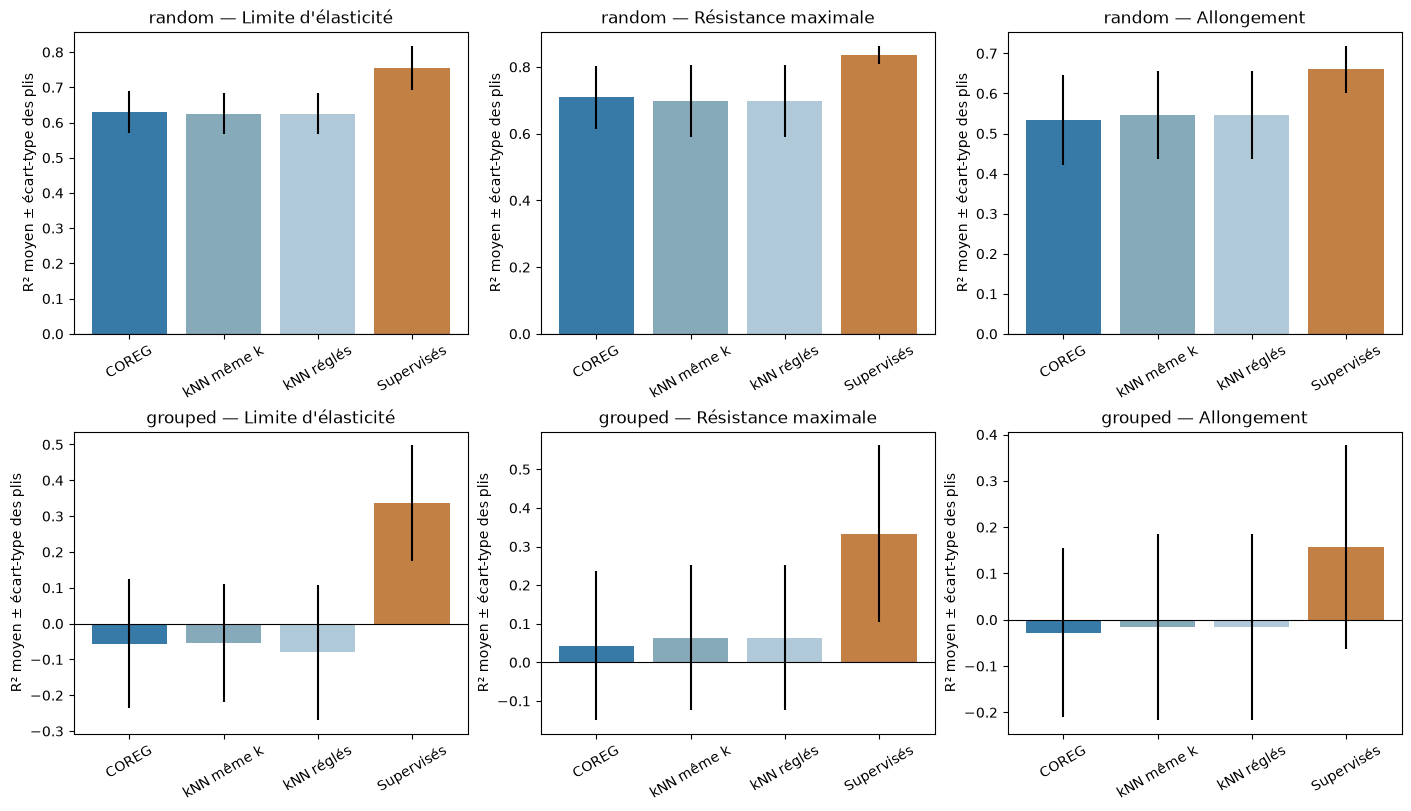

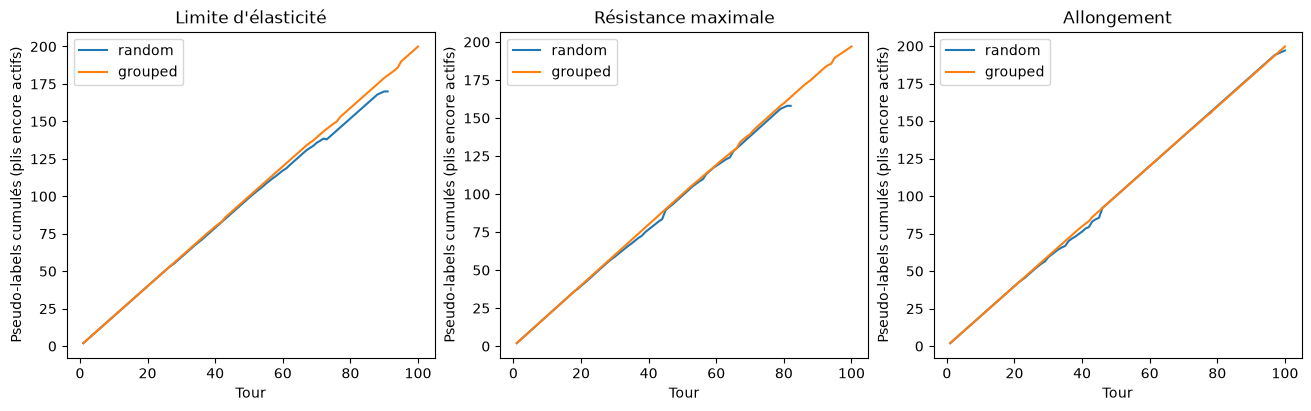

In [9]:

verifier="""import json,cloudpickle,pandas as pd,numpy as np,sys
from pathlib import Path
root=Path(sys.argv[1]);out=root/'data/processed/experiments/salh_coreg_v1'
master=pd.read_csv(root/'data/processed/modeling/master.csv').set_index('raw_row_id')
pred=pd.read_csv(out/'outer_predictions.csv');items=pd.read_csv(out/'model_artifacts.csv')
checks=[]
for r in items.itertuples(index=False):
 path=root/r.path;meta=json.loads(path.with_suffix('.json').read_text())
 with path.open('rb') as f: pipeline=cloudpickle.load(f)
 if r.role=='outer_train_only':
  pp=pred.loc[(pred.protocol==r.protocol)&(pred.target==r.target)&(pred.outer_fold==r.outer_fold)&(pred.method==r.method)]
  expected=pp.y_pred.to_numpy();actual=pipeline.predict(master.loc[pp.raw_row_id,meta['features']])
  np.testing.assert_allclose(actual,expected,rtol=1e-10,atol=1e-8)
 else:
  assert meta['do_not_use_for_fold_evaluation']
  assert np.isfinite(pipeline.predict(master.loc[meta['train_raw_row_ids'][:10],meta['features']])).all()
 checks.append({'path':r.path,'fresh_process_verified':True,'role':r.role})
print(json.dumps(checks))
"""
result=subprocess.run([sys.executable,'-c',verifier,str(PROJECT_ROOT)],check=True,capture_output=True,text=True,
    env=dict(os.environ,OPENBLAS_NUM_THREADS='1',MPLCONFIGDIR='/tmp/salh-matplotlib'))
show_saved(pd.DataFrame(json.loads(result.stdout)),'fresh_reload_checks.csv')
fig,axes=plt.subplots(2,3,figsize=(14,8),layout='constrained')
for row,protocol in enumerate(PROTOCOLS):
    for col,target in enumerate(SSL_TARGETS):
        ax=axes[row,col]
        selected=summary.loc[(summary.protocol==protocol)&(summary.target==target)&
            summary.method.isin(['coreg','matched_knn_pair','knn_pair','supervised_inner_selected'])]
        order=['coreg','matched_knn_pair','knn_pair','supervised_inner_selected']
        selected=selected.set_index('method').loc[order]
        ax.bar(range(4),selected.R2_mean,yerr=selected.R2_sd,color=['#377aa8','#87aabb','#afc9d8','#c28045'])
        ax.set_xticks(range(4),['COREG','kNN même k','kNN réglés','Supervisés'],rotation=30)
        ax.axhline(0,color='black',lw=.8)
        ax.set(title=protocol+' — '+TARGET_NAMES[target],ylabel='R² moyen ± écart-type des plis')
fig.savefig(OUT/'coreg_comparison.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
audit=pd.DataFrame(fit_rows);history=pd.DataFrame(iteration_rows)
for ax,target in zip(axes,SSL_TARGETS):
    for protocol in PROTOCOLS:
        h=history.loc[(history.stage=='outer')&(history.protocol==protocol)&(history.target==target)].copy()
        h['cumulative']=h.groupby(['outer_fold','k']).accepted.cumsum()
        ax.plot(h.groupby('iteration').cumulative.mean(),label=protocol)
    ax.set(title=TARGET_NAMES[target],xlabel='Tour',ylabel='Pseudo-labels cumulés (plis encore actifs)');ax.legend()
fig.savefig(OUT/'coreg_iterations.png',dpi=160);plt.show()


## Interprétation et traçabilité

Comparer d'abord COREG au même k sans pseudo-labels, puis aux kNN réglés et
aux meilleurs supervisés ; un progrès local n'assure pas un gain externe.
Les pools sont moins grands après déduplication et les deux protocoles répondent
à des usages distincts. Les conclusions chiffrées sont dans les sorties et le
[rapport COREG](../reports/14_coreg_training.md). Les performances Charpy et les
sensibilités à la fraction de labels ne sont pas revendiquées par ce notebook.


### Conclusion chiffrée après exécution

| Validation | Cible | MAE COREG | R² COREG | MAE même k | MAE sélection supervisée |
| --- | --- | --- | --- | --- | --- |
| random | yield_strength | 37.919 | 0.629 | 38.241 | 31.630 |
| random | uts | 33.037 | 0.709 | 33.319 | 23.861 |
| random | elongation | 2.402 | 0.535 | 2.392 | 2.054 |
| grouped | yield_strength | 71.074 | -0.056 | 70.817 | 56.757 |
| grouped | uts | 63.060 | 0.043 | 62.081 | 54.344 |
| grouped | elongation | 3.904 | -0.028 | 3.879 | 3.517 |

Les R² sont les moyennes des cinq plis, distinctes des R² OOF.
Les gains MAE OOF face au même k ne sont positifs que pour YS/UTS en aléatoire,
avec intervalles bootstrap descriptifs couvrant zéro ; les trois gains groupés
sont négatifs. COREG reste moins performant que la sélection supervisée dans
les six cas. Il constitue une expérience semi-supervisée évaluée ; les modèles
supervisés restent la référence principale pour cette cohorte et ce budget.
Les kNN groupés sans pseudo-labels sont eux-mêmes faibles : le gain local
d'entraînement ne résout pas le transfert entre séries. Les labels de U restent
inconnus, donc aucun taux d'exactitude des pseudo-labels n'est inventé.


In [10]:

source_nb=json.loads((PROJECT_ROOT/'notebooks/07_coreg.ipynb').read_text())
source_text='\n\n'.join(''.join(c['source']) for c in source_nb['cells'])
manifest={'protocol_version':'salh-coreg-v1','seed':42,'targets':SSL_TARGETS,'numeric_features':CORE16,
    'process':CAT,'imputer':'median','protocols':PROTOCOLS,'inductive':True,'label_budget':'all true train labels',
    'k_grid':K_GRID,'p':[1,2],'max_iter':100,'pool_size':100,'gain_tol':1e-12,
    'pool_policy':'unique transformed X excluding true-train X; smallest raw ID',
    'confidence_neighbors':'current Lj, including pseudo-labels','selection':'mean internal MAE',
    'validation':'existing 5 outer / 3 inner random and grouped partitions',
    'full_cv':'5-fold random seed1042 or GroupKFold5; unlabeled-only assignments seed1142',
    'versions':VERSIONS,'raw_sha256':preparation_manifest['raw_sha256'],
    'parent_manifests':{str((folder/'manifest.json').relative_to(PROJECT_ROOT)):
        hashlib.sha256((folder/'manifest.json').read_bytes()).hexdigest()
        for folder in [DATA,DIAGNOSTICS,RANDOM,GROUPED]},
    'notebook_source_sha256':hashlib.sha256(source_text.encode()).hexdigest(),
    'outer_evaluations':len(scores),'main_outer_coreg_fits':30,'coreg_fits_including_sensitivity':len(fit_rows),
    'models_exported':len(artifact_rows),'elapsed_seconds':time.perf_counter()-STARTED,
    'files':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.glob('*.csv')},
    'model_files':{str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in MODELS.rglob('*') if p.is_file()}}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False)+'\n')
assert len(scores)==180 and len(fit_rows)==576 and len(artifact_rows)==108
display(pd.Series({k:manifest[k] for k in ['outer_evaluations','coreg_fits_including_sensitivity','models_exported','elapsed_seconds']}))


outer_evaluations                   180.000000
coreg_fits_including_sensitivity    576.000000
models_exported                     108.000000
elapsed_seconds                     586.347406
dtype: float64